# Lab 12-10 · Noise in Circuits

Companion to [chapter 12-10](../../chapters/12-10-noise-in-circuits.md). Four parts: thermal noise and its spectrum; kT/C by simulating an RC circuit; 1/f noise and integration limits; and noise figure against source resistance. Run the cells in order.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

k, T = 1.380649e-23, 300.0
kT = k * T
rng = np.random.default_rng(1210)

## Part 1 · Thermal noise of 1 kΩ

White Gaussian samples at rate $f_s$ have a one-sided PSD of $2\sigma^2/f_s$; choosing $\sigma^2 = 4kTR\,f_s/2$ gives $4kTR$. Welch's method estimates the spectrum.

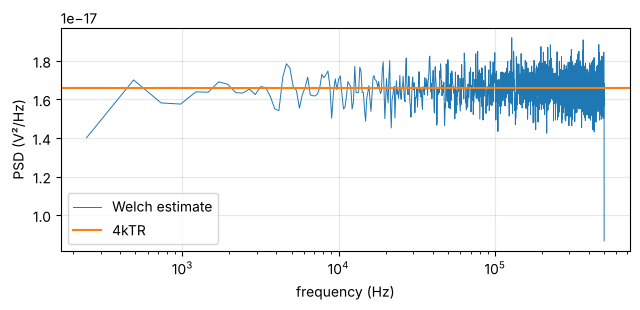

mean estimate 1.6528e-17 V²/Hz vs 4kTR = 1.6568e-17; density 4.066 nV/rtHz


In [2]:
R, fs, N = 1e3, 1e6, 2 ** 20
sigma = math.sqrt(4 * kT * R * fs / 2)
x = sigma * rng.standard_normal(N)
f, P = signal.welch(x, fs=fs, nperseg=4096)
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.semilogx(f[1:], P[1:], lw=0.7, label='Welch estimate'); ax.axhline(4 * kT * R, color='C1', label='4kTR')
ax.set_xlabel('frequency (Hz)'); ax.set_ylabel('PSD (V²/Hz)'); ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()
print(f"mean estimate {np.mean(P[1:-1]):.4e} V²/Hz vs 4kTR = {4 * kT * R:.4e}; density {math.sqrt(np.mean(P[1:-1])) * 1e9:.3f} nV/rtHz")

## Part 2 · kT/C by simulation (the chapter's guided exercise)

The capacitor voltage obeys $dv = -v/(RC)\,dt + (1/C)\sqrt{2kT/R}\,dW$: the resistor's thermal noise current, white with two-sided density $2kT/R$, charges $C$ while $R$ discharges it. The simulation below uses only that driving noise and a small Euler–Maruyama time step; it never uses the stationary variance, so the comparison with $\sqrt{kT/C}$ is a genuine test. **Predict first:** does a larger $R$ give a noisier capacitor?

In [3]:
C = 1e-12
for R in (1e3, 1e4, 1e5):
    tau = R * C
    dt = tau / 50                                   # Euler-Maruyama step, small against tau
    kick = math.sqrt(2 * kT / R * dt) / C           # charge kick from the noise current in one step, divided by C
    v = np.zeros(20000)                             # 20 000 independent capacitors, starting at 0 V
    for _ in range(500):                            # 10 time constants: long past the start-up transient
        v = v - v * dt / tau + kick * rng.standard_normal(v.size)
    print(f"R = {R / 1e3:6.0f} kΩ: simulated RMS {np.std(v) * 1e6:6.2f} µV; sqrt(kT/C) = {math.sqrt(kT / C) * 1e6:.2f} µV")

R =      1 kΩ: simulated RMS  64.48 µV; sqrt(kT/C) = 64.36 µV


R =     10 kΩ: simulated RMS  64.67 µV; sqrt(kT/C) = 64.36 µV


R =    100 kΩ: simulated RMS  64.89 µV; sqrt(kT/C) = 64.36 µV


## Part 3 · 1/f noise and integration limits

Synthesize 1/f noise by shaping white noise in the frequency domain, then integrate the theoretical spectrum $S_w(1 + f_c/f)$ ($S_w$ = (5 nV)²/Hz, $f_c$ = 100 kHz) from a lower limit $f_1$ to 1 MHz.

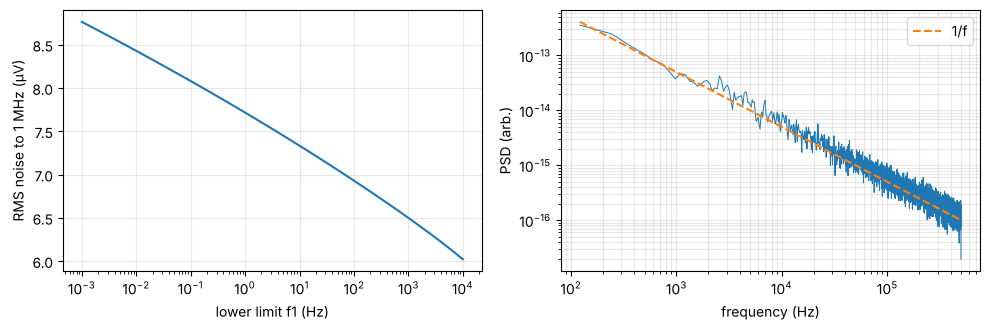

from 1 Hz: 7.716 µV (Example 12-10.3: 7.716 µV)


In [4]:
Sw, fc = (5e-9) ** 2, 1e5
f1s = np.logspace(-3, 4, 50)
rms = [math.sqrt(Sw * (1e6 - f1) + Sw * fc * math.log(1e6 / f1)) * 1e6 for f1 in f1s]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].semilogx(f1s, rms); ax[0].set_xlabel('lower limit f1 (Hz)'); ax[0].set_ylabel('RMS noise to 1 MHz (µV)'); ax[0].grid(True, alpha=0.3)
n = 2 ** 16; fr = np.fft.rfftfreq(n, 1e-6); W = rng.standard_normal(fr.size) + 1j * rng.standard_normal(fr.size)
W[0] = 0; W[1:] /= np.sqrt(fr[1:])
y = np.fft.irfft(W, n)
fw, Pw = signal.welch(y, fs=1e6, nperseg=8192)
ax[1].loglog(fw[1:], Pw[1:], lw=0.7); ax[1].loglog(fw[1:], Pw[5] * fw[5] / fw[1:], '--', label='1/f'); ax[1].legend()
ax[1].set_xlabel('frequency (Hz)'); ax[1].set_ylabel('PSD (arb.)'); ax[1].grid(True, which='both', alpha=0.3)
plt.tight_layout(); plt.show()
print(f"from 1 Hz: {rms[np.argmin(abs(f1s - 1))]:.3f} µV (Example 12-10.3: 7.716 µV)")

## Part 4 · Noise figure against source resistance

$e_n$ = 1 nV/√Hz, $i_n$ = 1 pA/√Hz.

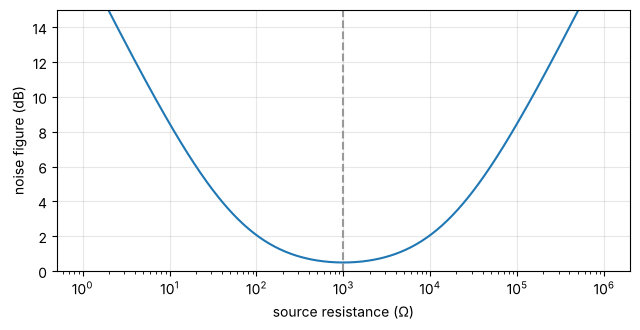

minimum NF 0.495 dB at 1017 Ω; at 50 Ω: 3.44 dB


In [5]:
en, inn = 1e-9, 1e-12
Rs = np.logspace(0, 6, 400)
F = (4 * kT * Rs + en ** 2 + (inn * Rs) ** 2) / (4 * kT * Rs)
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.semilogx(Rs, 10 * np.log10(F)); ax.axvline(en / inn, color='0.6', ls='--')
ax.set_xlabel('source resistance (Ω)'); ax.set_ylabel('noise figure (dB)'); ax.set_ylim(0, 15); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()
k0 = np.argmin(F); print(f"minimum NF {10 * math.log10(F[k0]):.3f} dB at {Rs[k0]:.0f} Ω; at 50 Ω: {10 * math.log10(F[np.argmin(abs(Rs - 50))]):.2f} dB")